## Prerequisites & Setup
Ensure that you have all the required dependencies installed. This notebook uses DINOv3 from HuggingFace to extract feature representations.

# **M5 Feature Vectors Representation**

This notebook documents an experiment with feature vector representations extracted using Meta's DINOv3 open-source model.

This notebook differs in the method used for dimension reduction compared to M3.


## **0. Importing**

In [31]:
import torch
import numpy as np
import torchvision
from transformers import pipeline
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from transformers import AutoImageProcessor, AutoModel
from tqdm.auto import tqdm
import h5py
import os
import kagglehub
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
import random

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### **0.1 Hugging face login**

In [ ]:
from huggingface_hub import login
login()

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "facebook/dinov3-vits16-pretrain-lvd1689m"
HDF5_FILE = "dino_features.h5"
print(f"Loading model: {model_name}")

model = AutoModel.from_pretrained(model_name).to(device).eval()

## **1. Loading features**


### **1.1 Reading the features into np.arrays**

In [4]:
with h5py.File('features/cifar10.h5', 'r') as f:
    cifar10_features = np.array(f['features'])
    cifar10_labels = np.array(f['labels'])

with h5py.File('features/cifar100.h5', 'r') as f:
    cifar100_features = np.array(f['features'])
    cifar100_labels = np.array(f['labels'])

with h5py.File('features/svhn.h5', 'r') as f:
    svhn_features = np.array(f['features'])
    svhn_labels = np.array(f['labels'])

with h5py.File('features/food101.h5', 'r') as f:
    food101_features = np.array(f['features'])
    food101_labels = np.array(f['labels'])

with h5py.File('features/pokemon.h5', 'r') as f:
    pokemon_features = np.array(f['features'])
    pokemon_labels = np.array(f['labels'])

## **2. t-distributed stochastic neighbor embedding (t-SNE)**

t-SNE is a **non-linear** dimensionality reduction technique used primarily for **visualization**. Its goal is to preserve the **local structure** of the data, revealing clusters.

### How it Works
1.  It models the probability that two points are "neighbors" in the high-dimensional space.
2.  It then tries to create a low-dimensional map (e.g., 2D or 3D) that preserves these neighborhood probabilities as well as possible.
3.  It uses a different probability distribution (the "t-distribution") in the low-D map to help separate clusters and avoid crowding.

### Key Characteristics
* **Non-linear:** It can capture complex, non-linear (e.g., curved) structures.
* **Local:** It's excellent at keeping points that are neighbors in high-D space as neighbors in the low-D map. This is why it's so good at showing clusters.
* **Stochastic (Probabilistic):** Running t-SNE multiple times on the same data *can* produce slightly different results. For reproducible research, always set the `random_state` parameter.
* **Slow:** It is computationally expensive, especially on large datasets (N > 10,000).
* **Axes are Meaningless:** The X and Y axes in a t-SNE plot do not have any specific, interpretable meaning.

**Use t-SNE for:**
* **Visualization:** Its primary purpose. Excellent for visualizing high-dimensional data in 2D or 3D.
* **Cluster Identification:** Revealing natural groupings (clusters) in your data that you might not otherwise see.



---

## Key Differences at a Glance

| Feature | PCA | t-SNE |
| :--- | :--- | :--- |
| **Algorithm** | Linear | **Non-linear** |
| **Preserves** | **Global Variance** (large distances) | **Local Neighborhoods** (small distances) |
| **Primary Goal** | Dimensionality Reduction, Pre-processing | **Visualization**, Cluster Identification |
| **Determinism** | Deterministic | Stochastic (probabilistic) |
| **Speed** | Fast | Slow (especially on large N) |
| **Interpretation** | Axes are meaningful (components) | Axes are **not** meaningful |
| **Distances** | Preserves global distances | **Global distances are meaningless!** |

### **2.1 t-SNE implementation**

In [5]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import time

In [6]:
def get_tsne_embedding(X, y, n_components=2, max_samples=None, perplexity=30.0):
    """
    Runs PCA and t-SNE on data for n_components (2 or 3).
    If max_samples=None, all data points are used.
    REMOVED random_state for non-deterministic results.
    """
    # Subsample if max_samples is set AND the dataset is larger
    if max_samples is not None and X.shape[0] > max_samples:
        print(f"Subsampling {max_samples} points from {X.shape[0]}...")
        indices = np.random.choice(X.shape[0], max_samples, replace=False)
        X_proc = X[indices]
        y_proc = y[indices]
    else:
        print(f"Using all {X.shape[0]} points.")
        X_proc = X
        y_proc = y

    print("Running PCA (n_components=50)...")
    pca = PCA(n_components=50)
    X_pca = pca.fit_transform(X_proc)
    print(f"PCA complete. Explained variance: {np.sum(pca.explained_variance_ratio_):.2f}")

    print(f"Running t-SNE (n_components={n_components})... (This may take a moment)")
    tsne = TSNE(
        n_components=n_components,
        perplexity=perplexity,
        learning_rate='auto',
        max_iter=1000,
        init='pca',
        n_jobs=-1
    )

    X_tsne = tsne.fit_transform(X_pca)

    return X_tsne, y_proc

In [7]:
tsne_results = {}
label_results = {}

### **2.2 CIFAR-10 and CIFAR-100**

In [ ]:
print("\nProcessing dataset: CIFAR-10")
start_time = time.time()

name = 'cifar10'
current_perplexity = 30.0

X_tsne, y_sampled = get_tsne_embedding(
    cifar10_features,
    cifar10_labels,
    perplexity=current_perplexity
)

tsne_results[name] = X_tsne
label_results[name] = y_sampled

end_time = time.time()
print(f"--- Finished {name} in {end_time - start_time:.2f} seconds ---")


Processing dataset: CIFAR-10
Using all 10000 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.58
Running t-SNE (n_components=2)... (This may take a moment)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


--- Finished cifar10 in 26.03 seconds ---


In [ ]:
print("\nProcessing dataset: CIFAR-100")
start_time = time.time()

name = 'cifar100'
current_perplexity = 30.0

X_tsne, y_sampled = get_tsne_embedding(
    cifar100_features,
    cifar100_labels,
    perplexity=current_perplexity
)

tsne_results[name] = X_tsne
label_results[name] = y_sampled

end_time = time.time()
print(f"--- Finished {name} in {end_time - start_time:.2f} seconds ---")


Processing dataset: CIFAR-100
Using all 10000 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.51
Running t-SNE (n_components=2)... (This may take a moment)


### **2.3 SVHN**

In [ ]:
print("\nProcessing dataset: SVHN")
start_time = time.time()

name = 'svhn'
current_perplexity = 30.0

X_tsne, y_sampled = get_tsne_embedding(
    svhn_features,
    svhn_labels,
    perplexity=current_perplexity
)

tsne_results[name] = X_tsne
label_results[name] = y_sampled

end_time = time.time()
print(f"--- Finished {name} in {end_time - start_time:.2f} seconds ---")


Processing dataset: SVHN
Using all 26032 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.79
Running t-SNE (n_components=2)... (This may take a moment)
--- Finished svhn in 758.41 seconds ---


### **2.4 FOOD101**

In [ ]:
print("\nProcessing dataset: FOOD101")
start_time = time.time()

name = 'food101'
current_perplexity = 30.0

X_tsne, y_sampled = get_tsne_embedding(
    food101_features,
    food101_labels,
    perplexity=current_perplexity
)

tsne_results[name] = X_tsne
label_results[name] = y_sampled

end_time = time.time()
print(f"--- Finished {name} in {end_time - start_time:.2f} seconds ---")


Processing dataset: FOOD101
Using all 25250 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.69
Running t-SNE (n_components=2)... (This may take a moment)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


--- Finished food101 in 75.97 seconds ---


### **2.5 Pokémon**

In [ ]:
print("\nProcessing dataset: Pokemon")
start_time = time.time()

name = 'pokemon'
current_perplexity = 30.0

X_tsne, y_sampled = get_tsne_embedding(
    pokemon_features,
    pokemon_labels,
    perplexity=current_perplexity
)

tsne_results[name] = X_tsne
label_results[name] = y_sampled

end_time = time.time()
print(f"--- Finished {name} in {end_time - start_time:.2f} seconds ---")


Processing dataset: Pokemon
Using all 21314 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.67
Running t-SNE (n_components=2)... (This may take a moment)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


--- Finished pokemon in 58.19 seconds ---


## **3. 2D visualization of t-SNE**

### **3.1 Implementation**

In [16]:
# Get Original classes names
orig_cifar10 = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=None)
orig_cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=None)
orig_svhn = torchvision.datasets.SVHN(root='./data', split='test', download=True, transform=None)
orig_food101 = torchvision.datasets.Food101(root='./data', split='test', download=True, transform=None)

100%|██████████| 170M/170M [00:03<00:00, 44.1MB/s]
100%|██████████| 169M/169M [00:05<00:00, 30.6MB/s]
100%|██████████| 64.3M/64.3M [00:04<00:00, 13.5MB/s]
100%|██████████| 5.00G/5.00G [03:39<00:00, 22.7MB/s]


In [17]:
cifar10_class_names = orig_cifar10.classes
cifar100_class_names = orig_cifar100.classes
svhn_class_names = [str(i) for i in range(10)]
food_class_names = orig_food101.classes

In [18]:
def visualize_tsne(tsne_features_2d, labels, class_names=None, title="t-SNE Visualization", figsize=(16, 8)):
    """
    Visualizes pre-computed 2D t-SNE features with an optional legend
    (either with class names or IDs) plotted next to the scatter plot.

    Args:
        tsne_features_2d (np.array): 2D array of t-SNE features (N, 2).
        labels (np.array): 1D array of corresponding labels (class IDs).
        class_names (list, optional): List of class names, where the index corresponds to the class ID.
                                      If provided, class names are used in the legend.
        title (str): Title for the t-SNE plot.
        figsize (tuple): Figure size for the entire figure (plot + legend).
    """

    fig, axes = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [3, 1]})

    unique_ids = np.unique(labels)
    num_classes = len(unique_ids)

    # Use 'nipy_spectral' for good color differentiation
    scatter = axes[0].scatter(
        tsne_features_2d[:, 0],
        tsne_features_2d[:, 1],
        c=labels,
        cmap='nipy_spectral',
        alpha=0.6,
        s=10 # Smaller points
    )
    axes[0].set_xlabel('t-SNE Dimension 1')
    axes[0].set_ylabel('t-SNE Dimension 2')
    axes[0].set_title(title)

    axes[1].axis('off')

    # Logic to display legend:
    # 1. If class_names are given AND there are 30 or fewer classes: show names.
    # 2. If no class_names, BUT 30 or fewer classes: show "Class ID: #"
    # 3. If > 30 classes: state that it's too many (and recommend plot_legend_with_ids).

    if class_names and num_classes <= 30:
        handles, _ = scatter.legend_elements()
        # Create labels from class_names using the actual unique IDs
        labels_text = [class_names[i] for i in unique_ids]
        axes[1].legend(handles, labels_text, loc='center left', title="Classes")

    elif num_classes <= 30:
        # No class names, but few enough to list IDs
        handles, _ = scatter.legend_elements()
        labels_text = [f"Class ID: {i}" for i in unique_ids]
        axes[1].legend(handles, labels_text, loc='center left', title="Class IDs")

    else:
        # Too many classes to display in a legend
        axes[1].text(0.5, 0.5,
                     f"Too many classes ({num_classes})\n"
                     f"to display in legend.\n\n"
                     f"Use plot_legend_with_ids()\n"
                     f"to see the mapping.",
                     ha='center', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()

In [24]:
def plot_legend_with_ids(class_names):
    """
    Plots a legend mapping class IDs to class names.
    (This is your function, unchanged - it's very
     useful for datasets like CIFAR-100 or Food-101)

    Args:
        class_names (list): List of class names, where the index corresponds to the class ID.
    """
    plt.figure(figsize=(6, max(5, len(class_names) * 0.3)))
    plt.axis('off')
    # Use a clear color map like tab10
    colors = plt.cm.get_cmap('tab10', 10)
    legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w',
                   label=f'{i}: {name}',
                   markerfacecolor=colors(i % 10),
                   markersize=10)
        for i, name in enumerate(class_names)
    ]
    plt.legend(handles=legend_elements, loc='center', title="Class IDs and Names")
    plt.title("Class ID to Name Mapping")
    plt.show()

print("Visualization functions defined.")

Visualization functions defined.


In [20]:
def plot_tsne_on_ax(ax, tsne_features_2d, labels, title=""):
    """
    A simple helper to draw a t-SNE scatter plot on a specific Matplotlib ax.
    """
    ax.scatter(
        tsne_features_2d[:, 0],
        tsne_features_2d[:, 1],
        c=labels,
        cmap='nipy_spectral',
        alpha=0.6,
        s=10 # You can adjust point size here
    )
    ax.set_title(title)
    ax.set_xlabel('t-SNE Dimension 1')
    ax.set_ylabel('t-SNE Dimension 2')
    ax.grid(False)

print("Helper function `plot_tsne_on_ax` defined.")

Helper function `plot_tsne_on_ax` defined.


In [21]:
def visualize_random_tsne(features, labels, class_names, num_random_classes=10,
                          title="t-SNE Visualization of Random Classes",
                          figsize=(16, 8), perplexity=30.0, max_samples=None):
    """
    Selects a random subset of classes, runs t-SNE, and visualizes them.

    Args:
        features (np.array): 2D array of ALL features.
        labels (np.array): 1D array of ALL corresponding labels (class IDs).
        class_names (list): List of ALL class names.
        num_random_classes (int): The number of random classes to select.
        title (str): Title for the t-SNE plot.
        figsize (tuple): Figure size for the entire figure (plot + legend).
        perplexity (float): Perplexity to pass to get_tsne_embedding.
        max_samples (int, optional): Max samples to pass to get_tsne_embedding.
                                     None means use all (filtered) points.
    """

    # --- 1. Filter Data (Same logic as your PCA function) ---
    all_class_ids = np.unique(labels)

    if len(all_class_ids) > num_random_classes:
        random_class_ids = random.sample(list(all_class_ids), num_random_classes)
        random_class_ids.sort()
    else:
        random_class_ids = list(all_class_ids)

    print(f"Selected {len(random_class_ids)} random classes: {random_class_ids}")

    # Create mask to select only features/labels from these classes
    mask = np.isin(labels, random_class_ids)
    filtered_features = features[mask]
    filtered_labels_original = labels[mask]

    # --- 2. Remap Labels (e.g., [1, 27, 89] -> [0, 1, 2]) ---
    old_id_to_new_id = {old_id: new_id for new_id, old_id in enumerate(random_class_ids)}
    filtered_labels_remapped = np.array([old_id_to_new_id[label] for label in filtered_labels_original])

    # Get the names for the legend
    filtered_class_names = [class_names[cid] if 0 <= cid < len(class_names) else f"ID {cid}" for cid in random_class_ids]

    # --- 3. Run t-SNE on the filtered data ---
    # We call your existing helper function here
    print(f"Running t-SNE on {len(filtered_features)} samples...")
    features_2d, labels_final = get_tsne_embedding(
        filtered_features,
        filtered_labels_remapped,
        max_samples=max_samples,
        perplexity=perplexity
    )
    print("t-SNE complete.")

    # --- 4. Plot the results ---
    fig, axes = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [3, 1]})

    unique_final_labels = np.unique(labels_final)
    num_classes_plot = len(unique_final_labels)
    cmap = plt.cm.nipy_spectral

    if num_classes_plot > 1:
        norm = plt.Normalize(vmin=np.min(unique_final_labels), vmax=np.max(unique_final_labels))
    else:
        norm = plt.Normalize(vmin=0, vmax=1)

    # Plot Scatter
    scatter = axes[0].scatter(
        features_2d[:, 0],
        features_2d[:, 1],
        c=labels_final,
        cmap=cmap,
        norm=norm,
        alpha=0.6,
        s=10
    )
    axes[0].set_xlabel('t-SNE Dimension 1')
    axes[0].set_ylabel('t-SNE Dimension 2')
    axes[0].set_title(title)

    # Plot Legend
    axes[1].axis('off')
    legend_elements = []

    # Create legend handles manually to match colors
    for new_id in unique_final_labels:
        if 0 <= new_id < len(filtered_class_names):
            class_name = filtered_class_names[new_id]
            label_text = f"{new_id}: {class_name}"
            color = cmap(norm(new_id))
            legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                           label=label_text,
                           markerfacecolor=color, markersize=10)
            )

    axes[1].legend(handles=legend_elements, loc='center left', title="Classes")

    plt.tight_layout()
    plt.show()

### **3.2 CIFAR-10 and CIFAR-100**

Visualizing CIFAR-10...


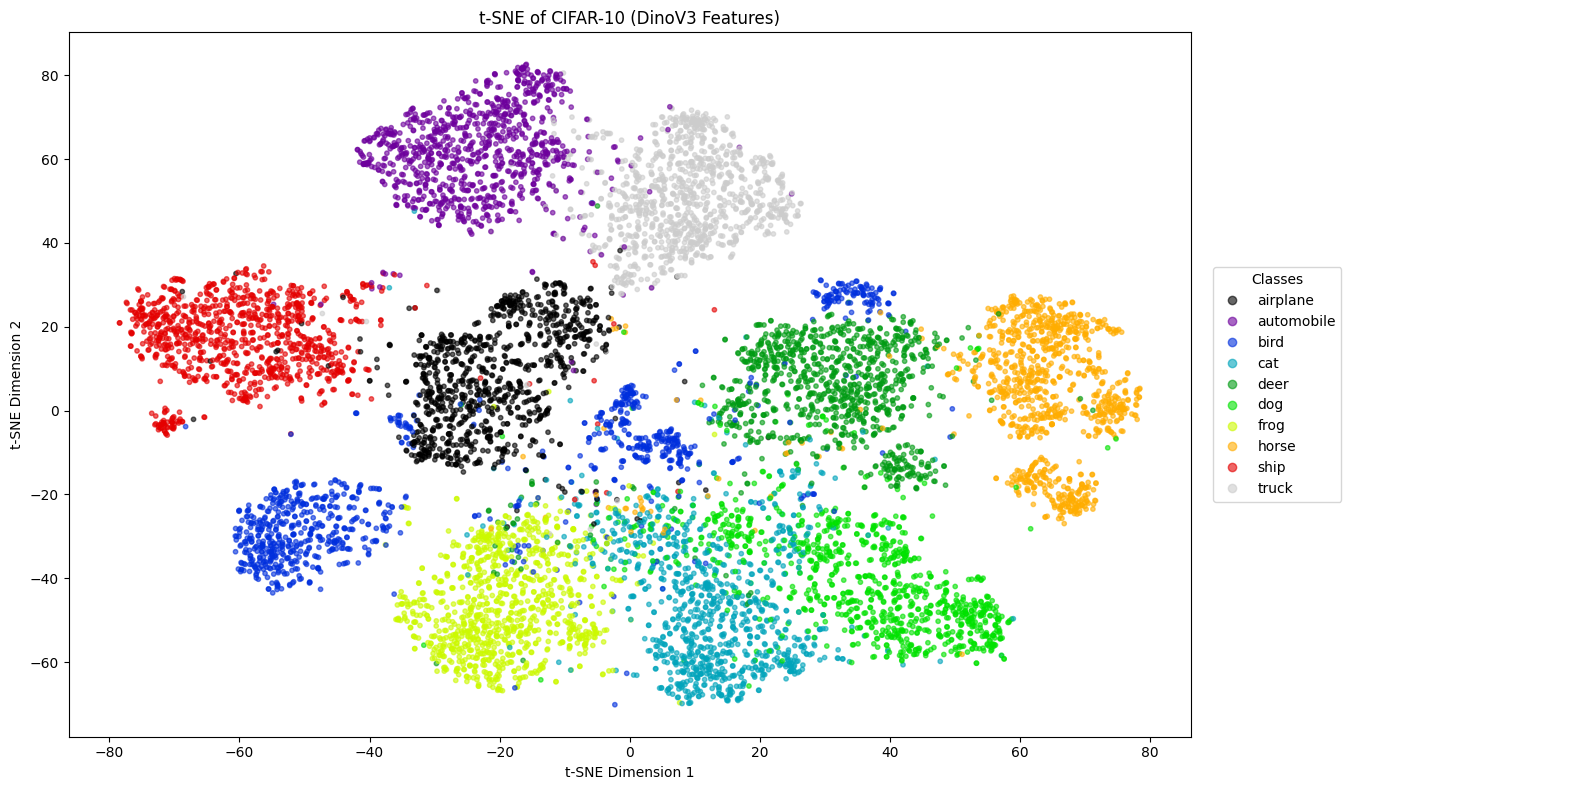

In [ ]:
print("Visualizing CIFAR-10...")
visualize_tsne(
    tsne_results['cifar10'],
    label_results['cifar10'],
    class_names=cifar10_class_names,
    title="t-SNE of CIFAR-10 (DinoV3 Features)"
)

Visualizing CIFAR-100...


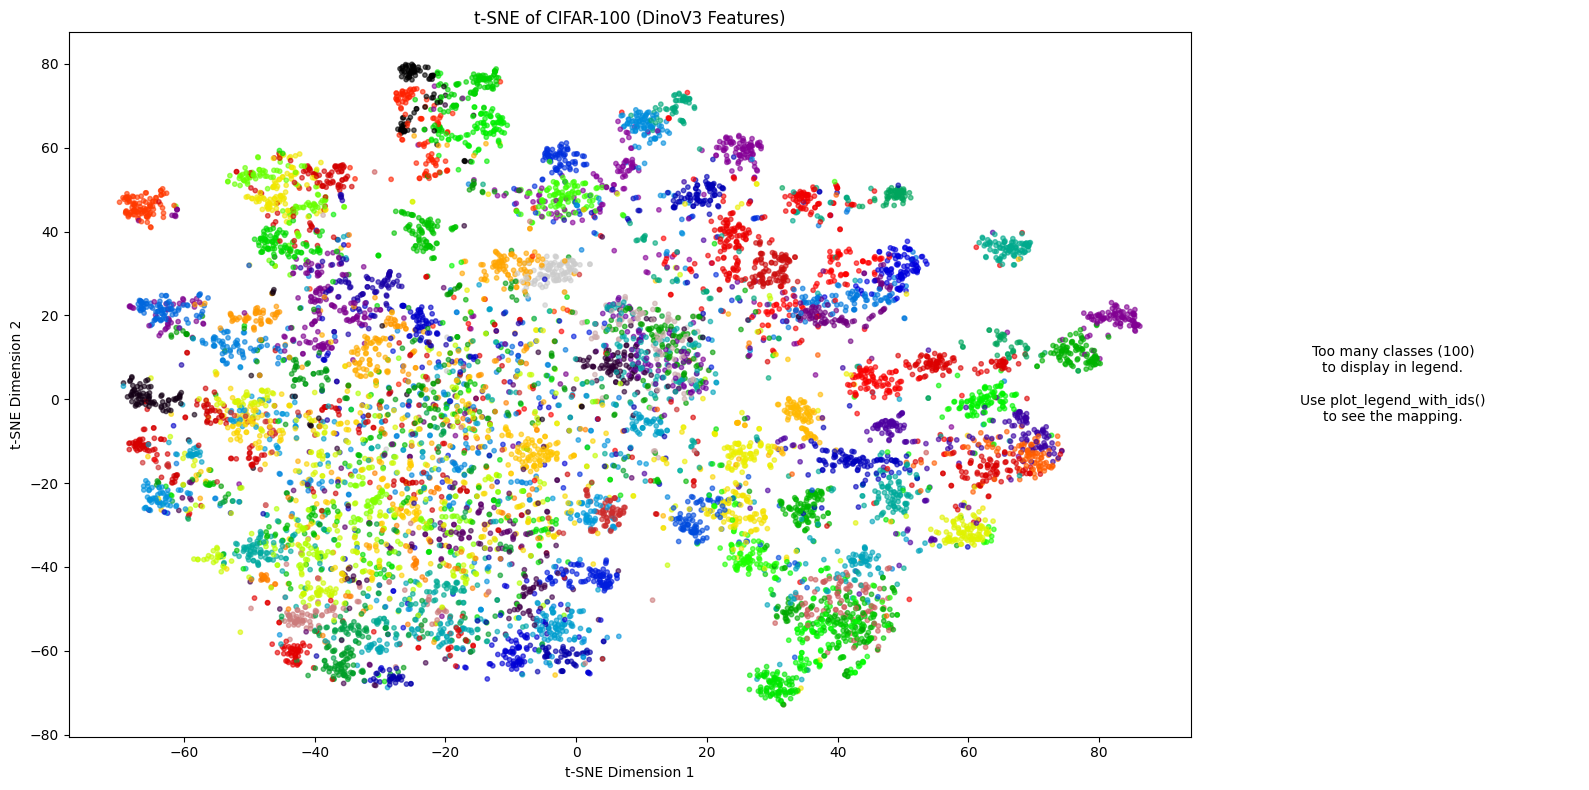

In [ ]:
print("Visualizing CIFAR-100...")
visualize_tsne(
    tsne_results['cifar100'],
    label_results['cifar100'],
    class_names=cifar100_class_names,
    title="t-SNE of CIFAR-100 (DinoV3 Features)"
)

In [ ]:
plot_legend_with_ids(cifar100_class_names)

Starting 2x2 t-SNE grid visualization for CIFAR-10...

--- Running t-SNE for grid cell 1/4 ---
Using all 10000 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.58
Running t-SNE (n_components=2)... (This may take a moment)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(



--- Running t-SNE for grid cell 2/4 ---
Using all 10000 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.58
Running t-SNE (n_components=2)... (This may take a moment)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(



--- Running t-SNE for grid cell 3/4 ---
Using all 10000 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.58
Running t-SNE (n_components=2)... (This may take a moment)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(



--- Running t-SNE for grid cell 4/4 ---
Using all 10000 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.58
Running t-SNE (n_components=2)... (This may take a moment)


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(



All 4 runs complete.


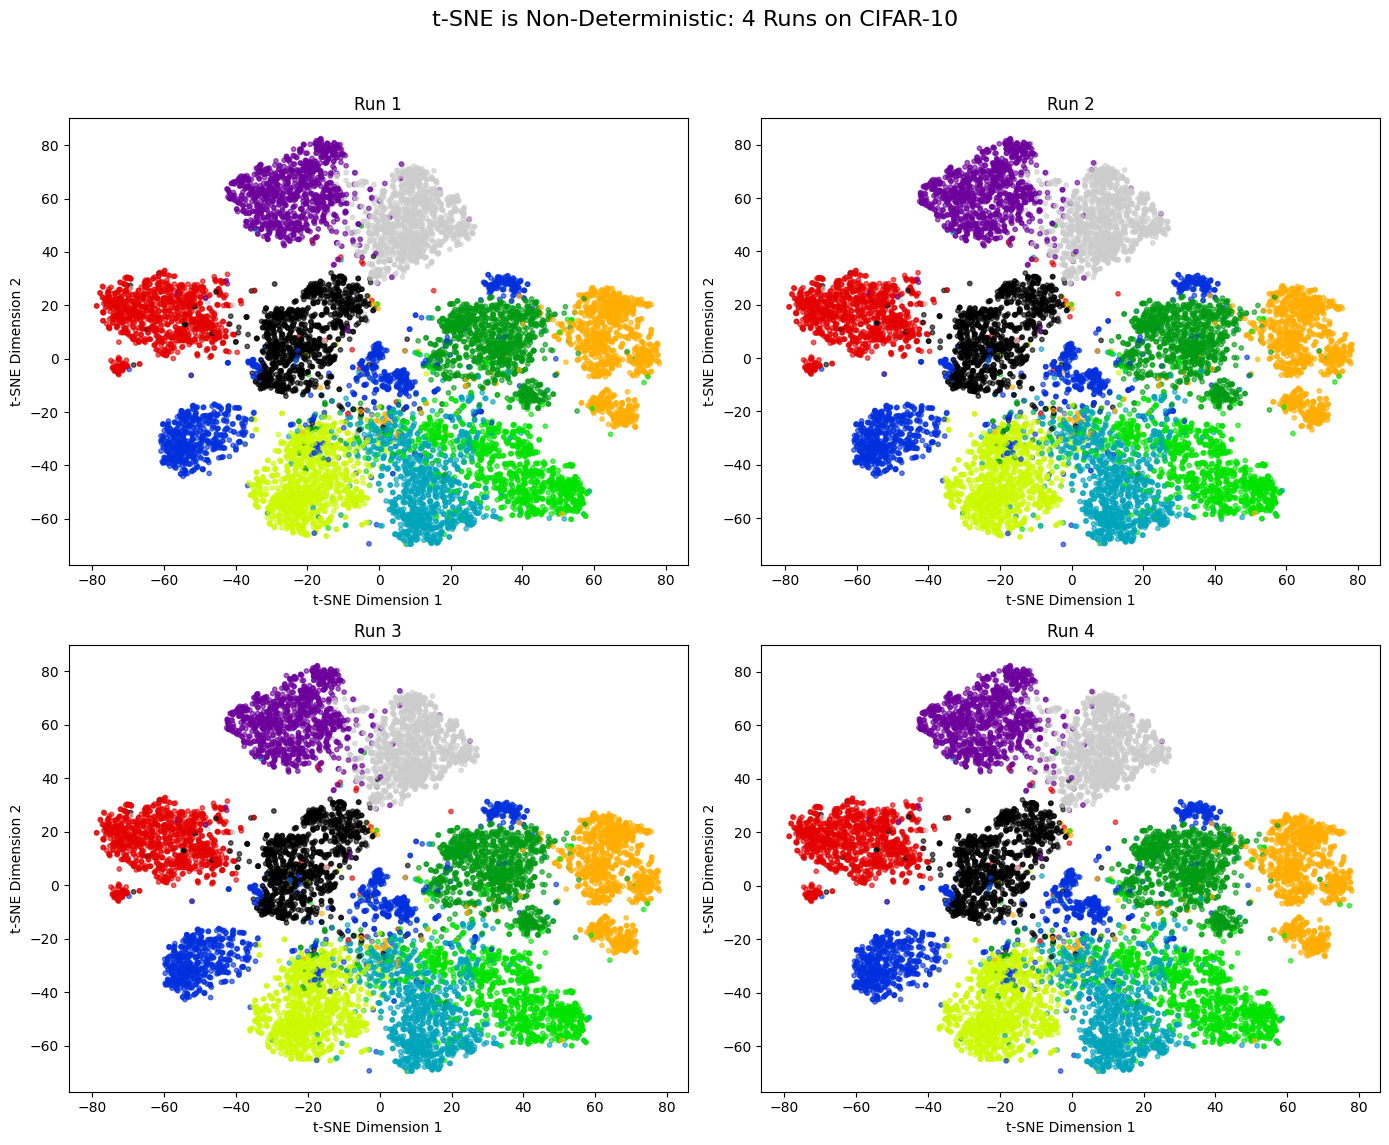

In [ ]:
dataset_features = cifar10_features
dataset_labels = cifar10_labels
dataset_name = 'CIFAR-10'

print(f"Starting 2x2 t-SNE grid visualization for {dataset_name}...")
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle(f"t-SNE is Non-Deterministic: 4 Runs on {dataset_name}", fontsize=16)

for i, ax in enumerate(axes.flat):
    print(f"\n--- Running t-SNE for grid cell {i+1}/4 ---")

    X_tsne, y_sampled = get_tsne_embedding(
        dataset_features,
        dataset_labels,
        perplexity=30.0
    )

    plot_tsne_on_ax(ax, X_tsne, y_sampled, f"Run {i+1}")

print("\nAll 4 runs complete.")
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust for the suptitle
plt.show()

### **3.3 SVHN**

Visualizing SVHN...


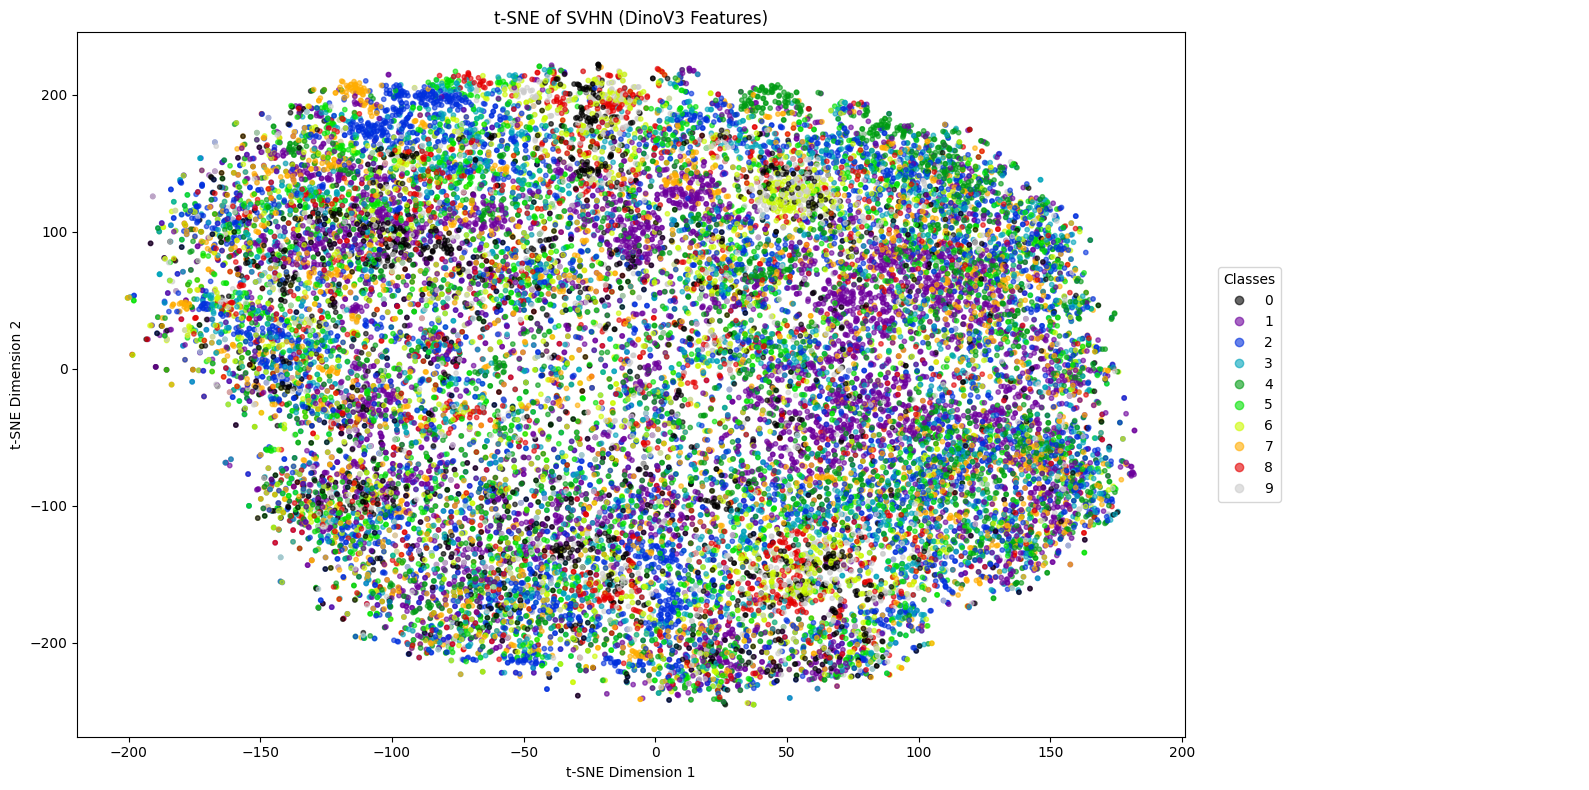

In [ ]:
print("Visualizing SVHN...")
visualize_tsne(
    tsne_results['svhn'],
    label_results['svhn'],
    class_names=svhn_class_names,
    title="t-SNE of SVHN (DinoV3 Features)"
)

In [ ]:
dataset_features = svhn_features
dataset_labels = svhn_labels
dataset_name = 'SVHN'

print(f"Starting 2x2 t-SNE grid visualization for {dataset_name}...")
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle(f"t-SNE is Non-Deterministic: 4 Runs on {dataset_name}", fontsize=16)

for i, ax in enumerate(axes.flat):
    print(f"\n--- Running t-SNE for grid cell {i+1}/4 ---")

    X_tsne, y_sampled = get_tsne_embedding(
        dataset_features,
        dataset_labels,
        perplexity=30.0
    )

    plot_tsne_on_ax(ax, X_tsne, y_sampled, f"Run {i+1}")

print("\nAll 4 runs complete.")
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust for the suptitle
plt.show()

### **3.4 FOOD101**

Visualizing FOOD101...


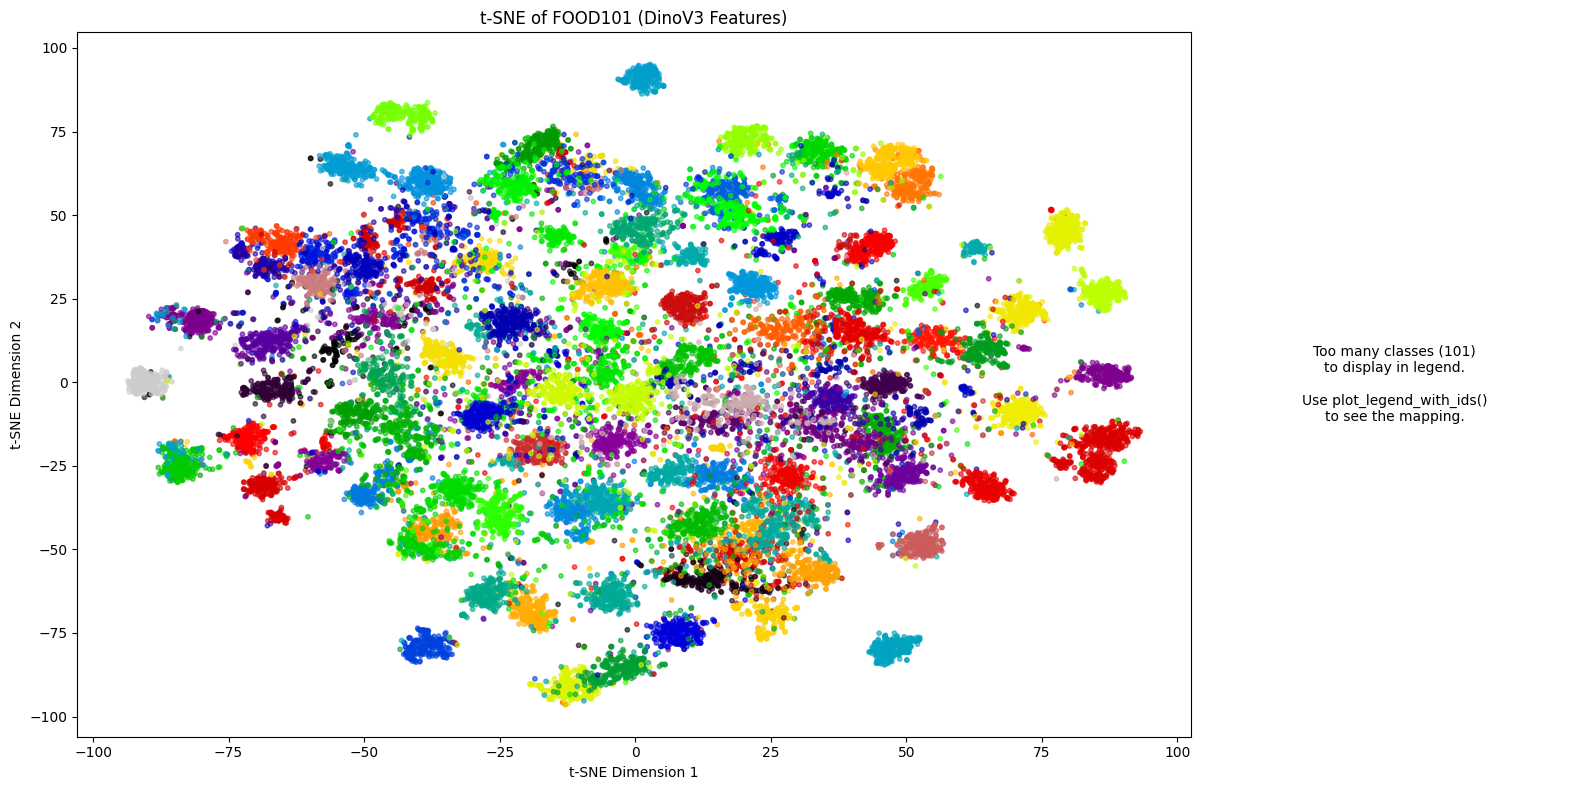

In [ ]:
print("Visualizing FOOD101...")
visualize_tsne(
    tsne_results['food101'],
    label_results['food101'],
    class_names=food_class_names,
    title="t-SNE of FOOD101 (DinoV3 Features)"
)

Selected 15 random classes: [np.int64(0), np.int64(1), np.int64(4), np.int64(9), np.int64(15), np.int64(22), np.int64(23), np.int64(29), np.int64(43), np.int64(57), np.int64(64), np.int64(81), np.int64(87), np.int64(96), np.int64(98)]
Running t-SNE on 3750 samples...
Using all 3750 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.71
Running t-SNE (n_components=2)... (This may take a moment)
t-SNE complete.


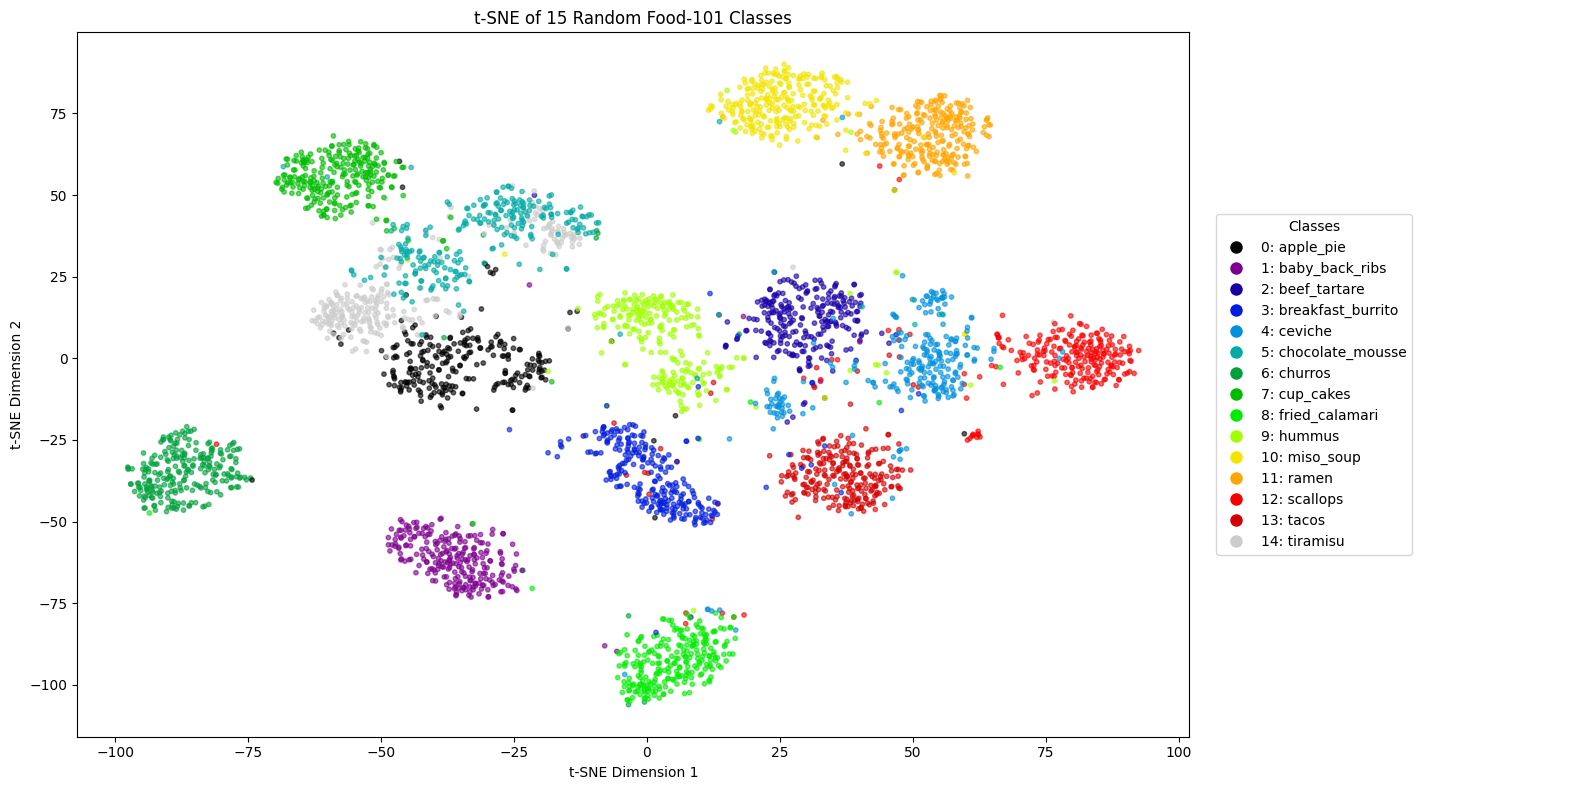

In [ ]:
food_class_names = orig_food101.classes

visualize_random_tsne(
    food101_features,
    food101_labels,
    food_class_names,
    num_random_classes=15,
    title="t-SNE of 15 Random Food-101 Classes",
    max_samples=None # Use all samples from the 15 classes
)

## **4. 3D computation of t-SNE**

In [9]:
tsne_results_3d = {}

### **4.1 CIFAR-10 and CIFAR-100**

In [10]:
print("\nProcessing dataset: CIFAR-10 (3D)")
start_time = time.time()

name = 'cifar10'
features, labels = cifar10_features, cifar10_labels
current_perplexity = 30.0

X_tsne_3d, y_sampled_3d = get_tsne_embedding(
    features,
    labels,
    n_components=3,
    perplexity=current_perplexity
)

tsne_results_3d[name] = X_tsne_3d
label_results[name] = y_sampled_3d

end_time = time.time()
print(f"--- Finished {name} (3D) in {end_time - start_time:.2f} seconds ---")


Processing dataset: CIFAR-10 (3D)
Using all 10000 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.58
Running t-SNE (n_components=3)... (This may take a moment)
--- Finished cifar10 (3D) in 70.16 seconds ---


In [11]:
print("\nProcessing dataset: CIFAR-100 (3D)")
start_time = time.time()

name = 'cifar100'
features, labels = cifar100_features, cifar100_labels
current_perplexity = 30.0

X_tsne_3d, y_sampled_3d = get_tsne_embedding(
    features,
    labels,
    n_components=3,
    perplexity=current_perplexity
)

tsne_results_3d[name] = X_tsne_3d
label_results[name] = y_sampled_3d

end_time = time.time()
print(f"--- Finished {name} (3D) in {end_time - start_time:.2f} seconds ---")


Processing dataset: CIFAR-100 (3D)
Using all 10000 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.51
Running t-SNE (n_components=3)... (This may take a moment)
--- Finished cifar100 (3D) in 72.06 seconds ---


### **4.2 SVHN**

In [12]:
print("\nProcessing dataset: SVHN (3D)")
start_time = time.time()

name = 'svhn'
features, labels = svhn_features, svhn_labels
current_perplexity = 30.0

X_tsne_3d, y_sampled_3d = get_tsne_embedding(
    features,
    labels,
    n_components=3,
    perplexity=current_perplexity
)

tsne_results_3d[name] = X_tsne_3d
label_results[name] = y_sampled_3d

end_time = time.time()
print(f"--- Finished {name} (3D) in {end_time - start_time:.2f} seconds ---")


Processing dataset: SVHN (3D)
Using all 26032 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.79
Running t-SNE (n_components=3)... (This may take a moment)
--- Finished svhn (3D) in 265.06 seconds ---


### **4.3 FOOD101**

In [13]:
print("\nProcessing dataset: FOOD101 (3D)")
start_time = time.time()

name = 'food101'
features, labels = food101_features, food101_labels
current_perplexity = 30.0

X_tsne_3d, y_sampled_3d = get_tsne_embedding(
    features,
    labels,
    n_components=3,
    perplexity=current_perplexity
)

tsne_results_3d[name] = X_tsne_3d
label_results[name] = y_sampled_3d

end_time = time.time()
print(f"--- Finished {name} (3D) in {end_time - start_time:.2f} seconds ---")


Processing dataset: FOOD101 (3D)
Using all 25250 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.69
Running t-SNE (n_components=3)... (This may take a moment)
--- Finished food101 (3D) in 219.08 seconds ---


## **5. 3D Plotting**

### **5.1 Importing**

In [14]:
from mpl_toolkits.mplot3d import Axes3D

In [15]:
def visualize_tsne_3d(tsne_features_3d, labels, class_names=None, title="3D t-SNE Visualization", figsize=(16, 8)):
    """
    Visualizes pre-computed 3D t-SNE features with an optional legend
    (either with class names or IDs) plotted next to the scatter plot.

    Args:
        tsne_features_3d (np.array): 3D array of t-SNE features (N, 3).
        labels (np.array): 1D array of corresponding labels (class IDs).
        class_names (list, optional): List of class names.
        title (str): Title for the t-SNE plot.
        figsize (tuple): Figure size for the entire figure (plot + legend).
    """

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(1, 2, width_ratios=[3, 1])
    ax_tsne = fig.add_subplot(gs[0], projection='3d')
    ax_legend = fig.add_subplot(gs[1])

    unique_ids = np.unique(labels)
    num_classes = len(unique_ids)

    if len(unique_ids) > 1:
        norm = plt.Normalize(vmin=unique_ids.min(), vmax=unique_ids.max())
    else:
        norm = plt.Normalize(vmin=unique_ids[0] - 0.5, vmax=unique_ids[0] + 0.5)

    scatter = ax_tsne.scatter(
        tsne_features_3d[:, 0], # X-axis
        tsne_features_3d[:, 1], # Y-axis
        tsne_features_3d[:, 2], # Z-axis
        c=labels,
        cmap='nipy_spectral',
        norm=norm,
        alpha=0.6,
        s=10
    )
    ax_tsne.set_xlabel('t-SNE Dimension 1')
    ax_tsne.set_ylabel('t-SNE Dimension 2')
    ax_tsne.set_zlabel('t-SNE Dimension 3')
    ax_tsne.set_title(title)

    ax_legend.axis('off')

    if class_names and num_classes <= 30:
        handles, _ = scatter.legend_elements()
        labels_text = [class_names[i] for i in unique_ids]
        ax_legend.legend(handles, labels_text, loc='center left', title="Classes")

    elif num_classes <= 30:
        handles, _ = scatter.legend_elements()
        labels_text = [f"Class ID: {i}" for i in unique_ids]
        ax_legend.legend(handles, labels_text, loc='center left', title="Class IDs")

    else:
        ax_legend.text(0.5, 0.5,
                     f"Too many classes ({num_classes})\n"
                     f"to display in legend.\n\n"
                     f"Use plot_legend_with_ids()\n"
                     f"to see the mapping.",
                     ha='center', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()

In [29]:
def visualize_random_tsne_3d(features, labels, class_names, num_random_classes=10,
                             title="3D t-SNE Visualization of Random Classes",
                             figsize=(16, 8), perplexity=30.0, max_samples=None):
    """
    Selects a random subset of classes, runs 3D t-SNE, and visualizes them.

    Args:
        features (np.array): 2D array of ALL features.
        labels (np.array): 1D array of ALL corresponding labels (class IDs).
        class_names (list): List of ALL class names.
        num_random_classes (int): The number of random classes to select.
        title (str): Title for the t-SNE plot.
        figsize (tuple): Figure size for the entire figure (plot + legend).
        perplexity (float): Perplexity to pass to get_tsne_embedding.
        max_samples (int, optional): Max samples to pass to get_tsne_embedding.
                                     None means use all (filtered) points.
    """

    # --- 1. Filter Data (Same logic as your 2D function) ---
    all_class_ids = np.unique(labels)

    if len(all_class_ids) > num_random_classes:
        random_class_ids = random.sample(list(all_class_ids), num_random_classes)
        random_class_ids.sort()
    else:
        random_class_ids = list(all_class_ids)

    print(f"Selected {len(random_class_ids)} random classes: {random_class_ids}")

    mask = np.isin(labels, random_class_ids)
    filtered_features = features[mask]
    filtered_labels_original = labels[mask]

    # --- 2. Remap Labels (Same logic as your 2D function) ---
    old_id_to_new_id = {old_id: new_id for new_id, old_id in enumerate(random_class_ids)}
    filtered_labels_remapped = np.array([old_id_to_new_id[label] for label in filtered_labels_original])
    filtered_class_names = [class_names[cid] if 0 <= cid < len(class_names) else f"ID {cid}" for cid in random_class_ids]

    # --- 3. Run 3D t-SNE (MODIFIED) ---
    print(f"Running 3D t-SNE on {len(filtered_features)} samples...")
    features_3d, labels_final = get_tsne_embedding(
        filtered_features,
        filtered_labels_remapped,
        n_components=3, # <-- The key change to get 3D data
        max_samples=max_samples,
        perplexity=perplexity
    )
    print("t-SNE complete.")

    # --- 4. Plot the 3D results (MODIFIED) ---
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(1, 2, width_ratios=[3, 1])
    ax_tsne = fig.add_subplot(gs[0], projection='3d') # <-- 3D projection
    ax_legend = fig.add_subplot(gs[1])

    unique_final_labels = np.unique(labels_final)
    num_classes_plot = len(unique_final_labels)
    cmap = plt.cm.nipy_spectral

    if num_classes_plot > 1:
        norm = plt.Normalize(vmin=np.min(unique_final_labels), vmax=np.max(unique_final_labels))
    else:
        norm = plt.Normalize(vmin=0, vmax=1)

    # Plot 3D Scatter
    scatter = ax_tsne.scatter(
        features_3d[:, 0], # X-axis
        features_3d[:, 1], # Y-axis
        features_3d[:, 2], # Z-axis
        c=labels_final,
        cmap=cmap,
        norm=norm,
        alpha=0.6,
        s=10
    )
    ax_tsne.set_xlabel('t-SNE Dimension 1')
    ax_tsne.set_ylabel('t-SNE Dimension 2')
    ax_tsne.set_zlabel('t-SNE Dimension 3') # <-- Z label
    ax_tsne.set_title(title)

    # Plot Legend (Same logic as your 2D function)
    ax_legend.axis('off')
    legend_elements = []

    for new_id in unique_final_labels:
        if 0 <= new_id < len(filtered_class_names):
            class_name = filtered_class_names[new_id]
            label_text = f"{new_id}: {class_name}"
            color = cmap(norm(new_id))
            legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                           label=label_text,
                           markerfacecolor=color, markersize=10)
            )

    ax_legend.legend(handles=legend_elements, loc='center left', title="Classes")

    plt.tight_layout()
    plt.show()

### **5.2 CIFAR-10/CIFAR-100**

Visualizing 3D t-SNE for CIFAR-10...


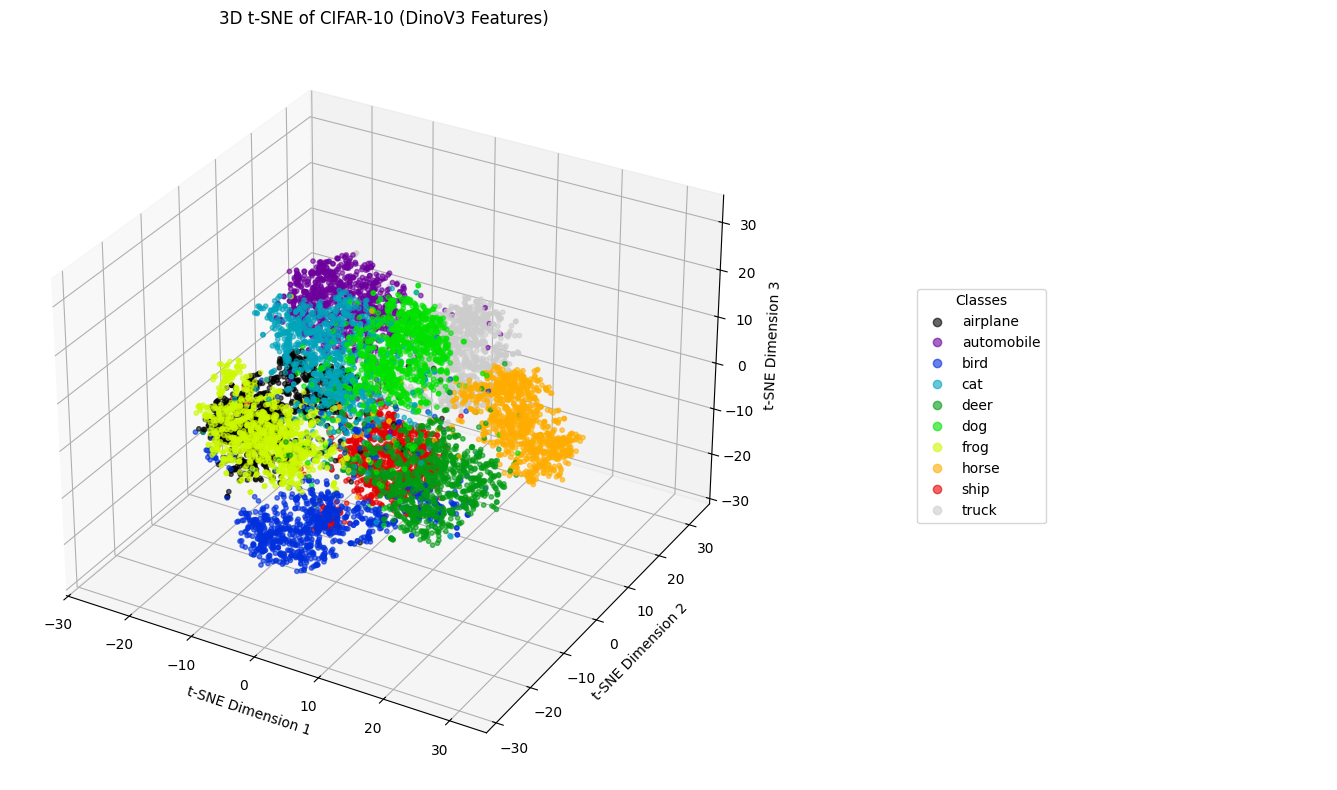

In [22]:
print("Visualizing 3D t-SNE for CIFAR-10...")
visualize_tsne_3d(
        tsne_results_3d['cifar10'],
        label_results['cifar10'],
        class_names=cifar10_class_names,
        title="3D t-SNE of CIFAR-10 (DinoV3 Features)"
    )

Visualizing 3D t-SNE for CIFAR-100...


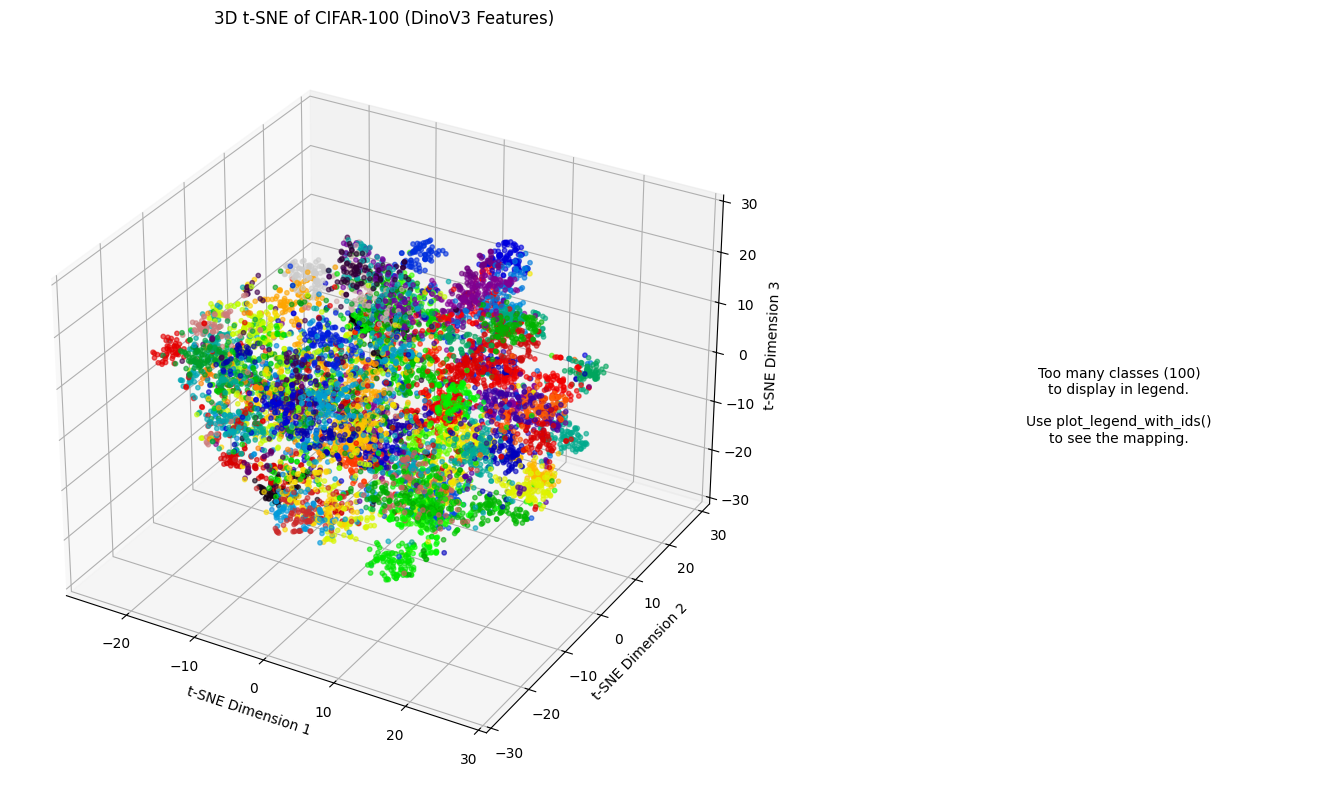

In [23]:
print("Visualizing 3D t-SNE for CIFAR-100...")
visualize_tsne_3d(
        tsne_results_3d['cifar100'],
        label_results['cifar100'],
        class_names=cifar100_class_names,
        title="3D t-SNE of CIFAR-100 (DinoV3 Features)"
    )

Selected 10 random classes: [np.int64(3), np.int64(32), np.int64(63), np.int64(64), np.int64(66), np.int64(79), np.int64(89), np.int64(91), np.int64(93), np.int64(96)]
Running 3D t-SNE on 1000 samples...
Using all 1000 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.63
Running t-SNE (n_components=3)... (This may take a moment)
t-SNE complete.


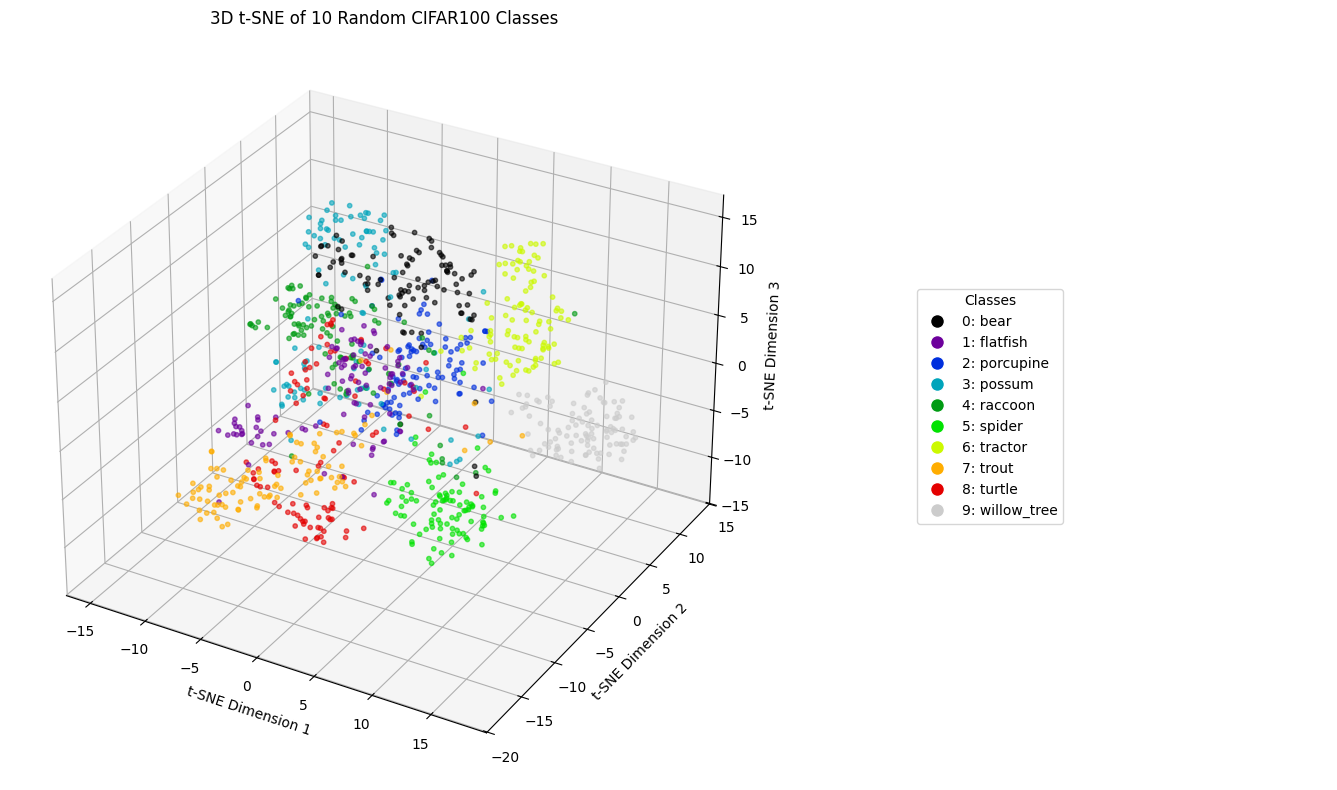

In [34]:
visualize_random_tsne_3d(
    cifar100_features,
    cifar100_labels,
    cifar100_class_names,
    num_random_classes=10,
    title="3D t-SNE of 10 Random CIFAR100 Classes",
    max_samples=None
)

### **5.3 SVHN**

Visualizing 3D t-SNE for SVHN...


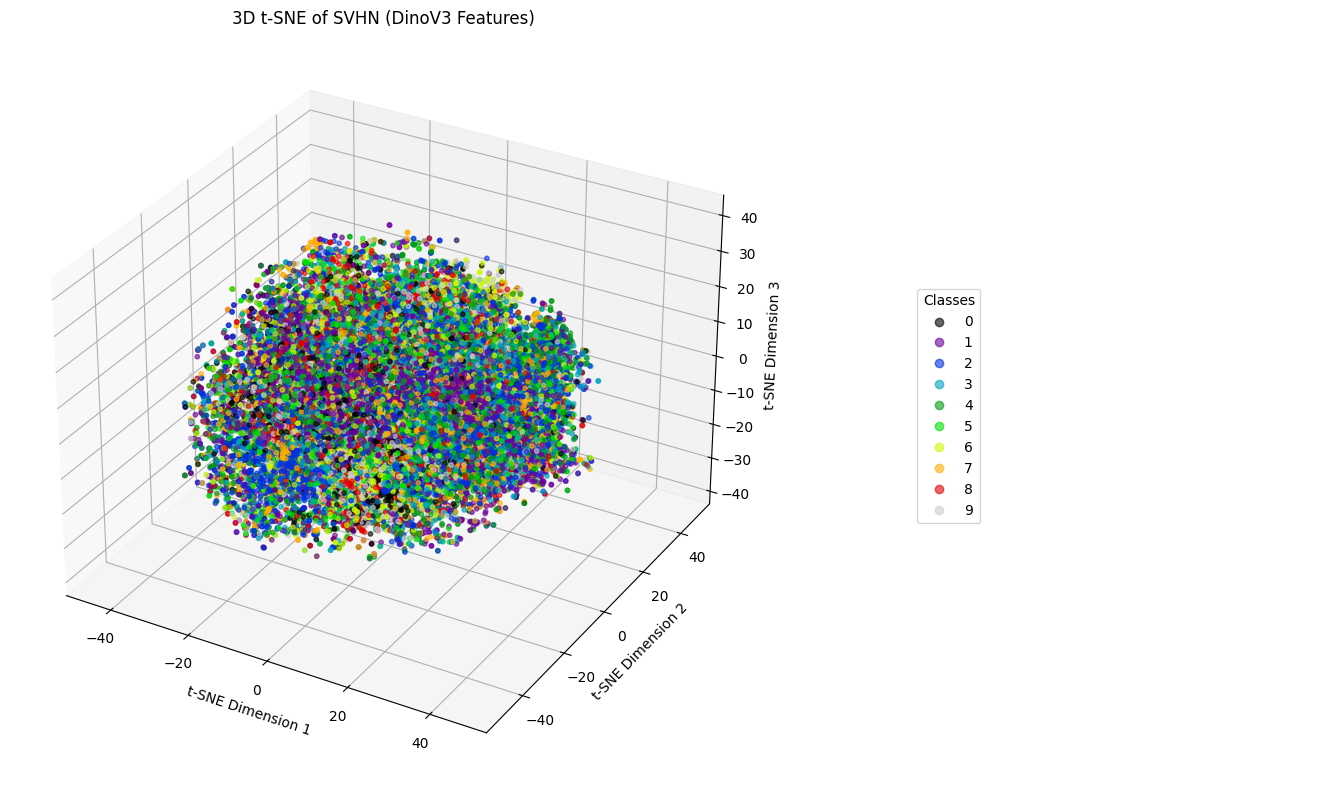

In [26]:
print("Visualizing 3D t-SNE for SVHN...")
visualize_tsne_3d(
        tsne_results_3d['svhn'],
        label_results['svhn'],
        class_names=svhn_class_names,
        title="3D t-SNE of SVHN (DinoV3 Features)"
    )

Selected 3 random classes: [np.int64(2), np.int64(3), np.int64(5)]
Running 3D t-SNE on 9415 samples...
Using all 9415 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.81
Running t-SNE (n_components=3)... (This may take a moment)
t-SNE complete.


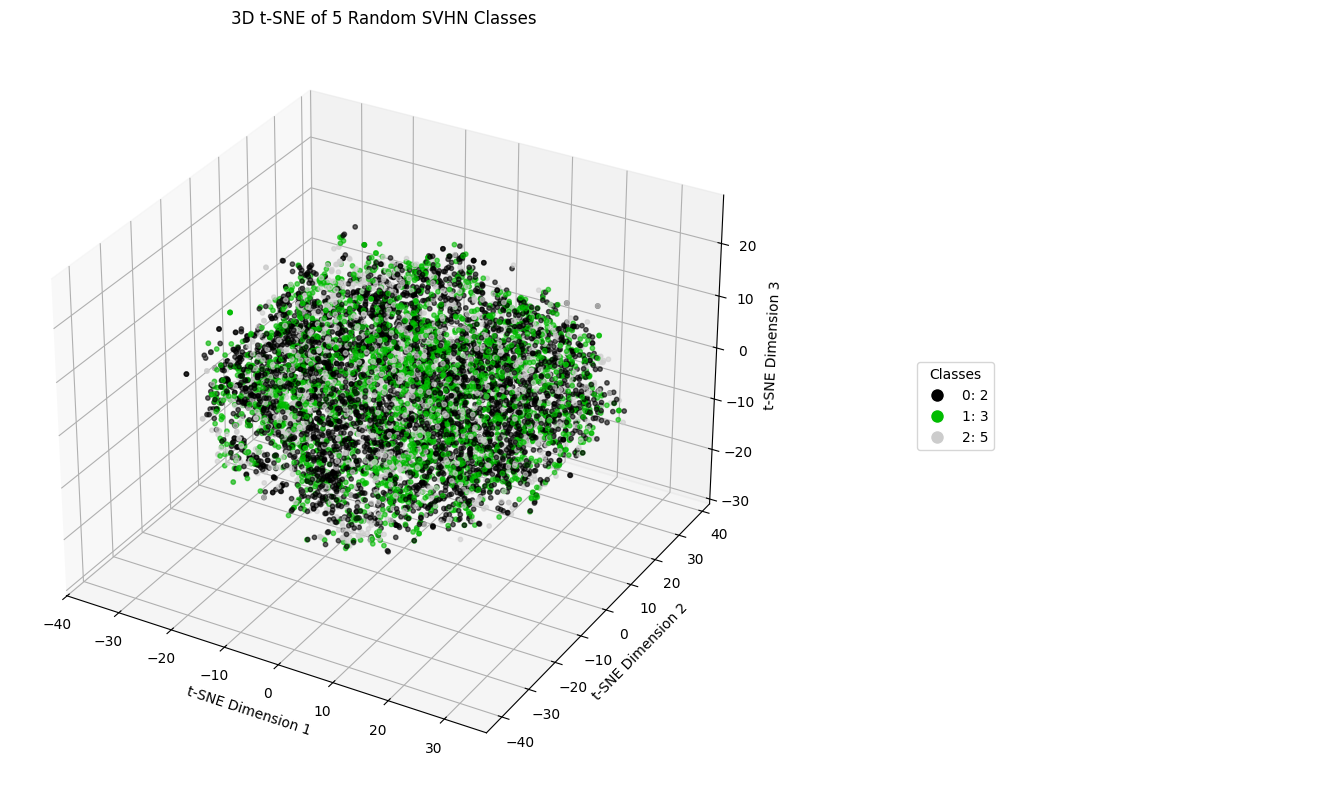

In [33]:
visualize_random_tsne_3d(
    svhn_features,
    svhn_labels,
    svhn_class_names,
    num_random_classes=3,
    title="3D t-SNE of 5 Random SVHN Classes",
    max_samples=None
)

### **5.4 FOOD101**

Visualizing 3D t-SNE for FOOD101...


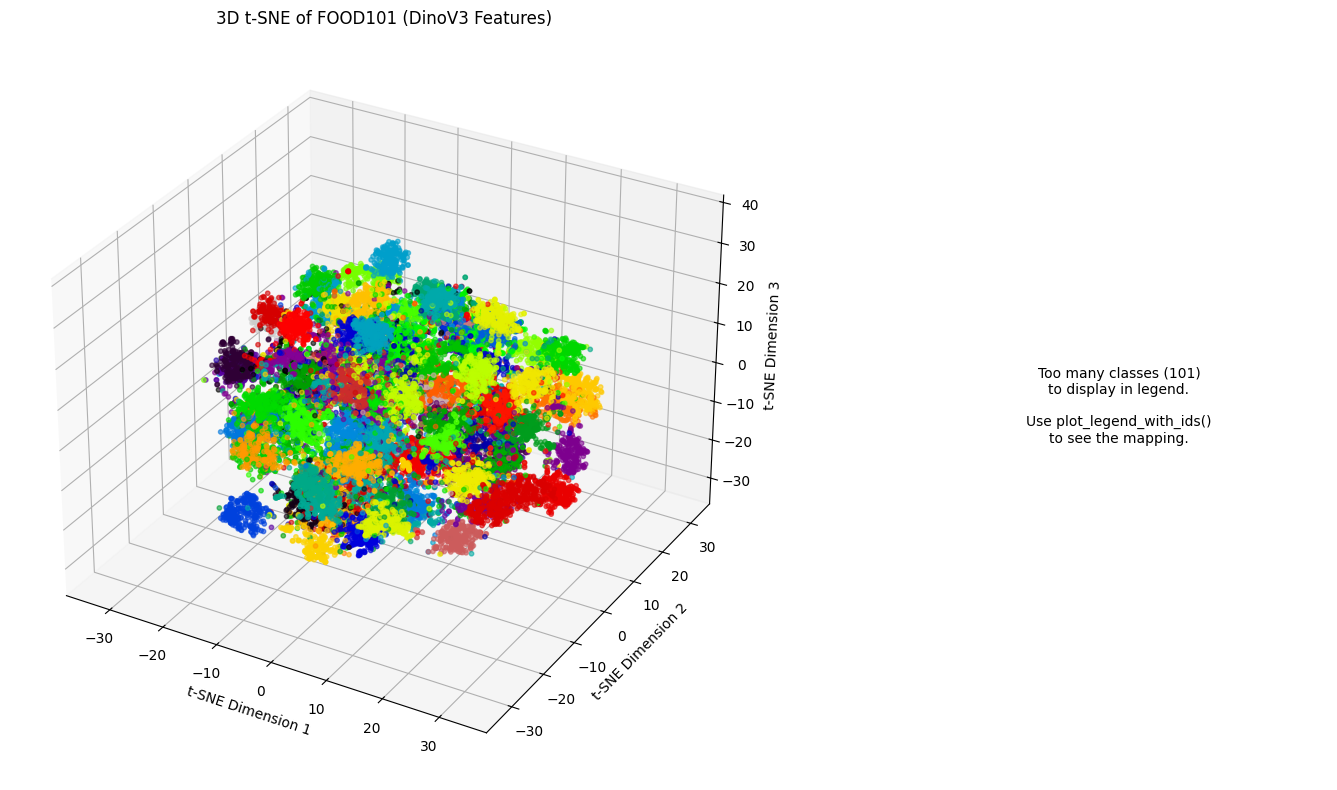

In [27]:
print("Visualizing 3D t-SNE for FOOD101...")
visualize_tsne_3d(
        tsne_results_3d['food101'],
        label_results['food101'],
        class_names=svhn_class_names,
        title="3D t-SNE of FOOD101 (DinoV3 Features)"
    )

Selected 5 random classes: [np.int64(11), np.int64(24), np.int64(33), np.int64(75), np.int64(83)]
Running 3D t-SNE on 1250 samples...
Using all 1250 points.
Running PCA (n_components=50)...
PCA complete. Explained variance: 0.79
Running t-SNE (n_components=3)... (This may take a moment)
t-SNE complete.


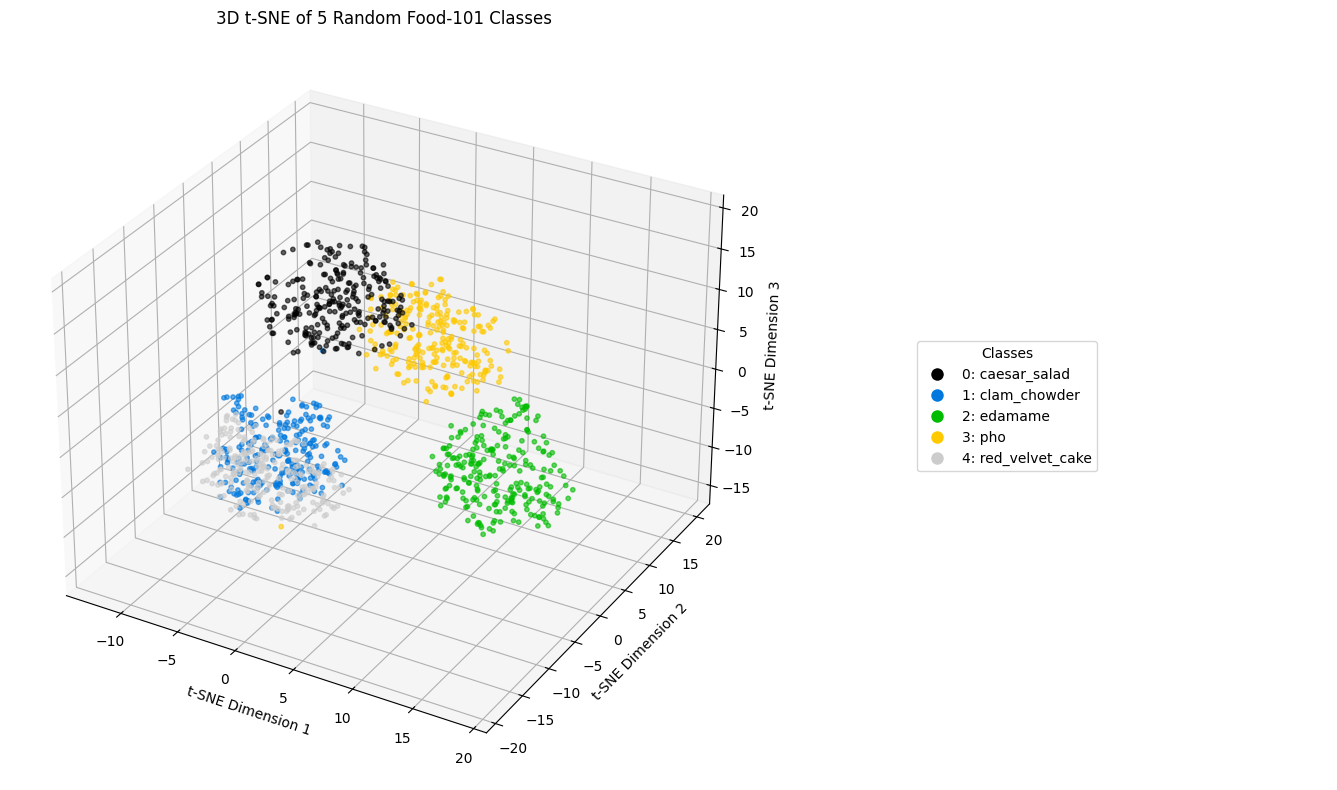

In [32]:
visualize_random_tsne_3d(
    food101_features,
    food101_labels,
    food_class_names,
    num_random_classes=5,
    title="3D t-SNE of 5 Random Food-101 Classes",
    max_samples=None # Use all samples from the 15 classes
)